# Gradient Boosting Regression — From Residuals to Additive Models

## 1. Definition
Gradient boosting builds an additive model stage by stage. At each round it fits a new weak learner to the negative gradient of the loss with respect to current predictions. For squared-error regression, this negative gradient is proportional to the residual.

## 2. Mathematical derivation
Let \(F_0(x)\) be an initial constant model. At round m, compute pseudo-residuals

\[
r_{im}=-\left[\frac{\partial L(y_i,F(x_i))}{\partial F(x_i)}\right]_{F=F_{m-1}}.
\]

Fit a weak learner \(h_m(x)\) to \((x_i,r_{im})\), then update \(F_m(x)=F_{m-1}(x)+\eta\,\gamma_m h_m(x)\), where \(\eta\) is the learning rate and \(\gamma_m\) may be chosen by line search or leaf-wise optimization. For squared error with a standard mean initialization, residuals are \(y_i-F_{m-1}(x_i)\).

## 3. Why it works; limitations
Each stage approximates a steepest-descent direction in function space. The weak learner constrains which directions can be represented, while shrinkage controls the step size. This is greedy optimization, so it does not generally guarantee the global best additive model. Too many rounds or too-deep trees can overfit.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_friedman1
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

SEED = 42
X, y = make_friedman1(n_samples=1200, n_features=10, noise=1.5, random_state=SEED)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)


## 4. Gradient boosting from scratch

We fit regression trees to current residuals and add their predictions with shrinkage. This educational version uses the tree's leaf means as residual corrections. It is a simple squared-error gradient boosting implementation, not a reimplementation of every optimization detail in scikit-learn.

Scratch test MSE: 5.130261804121785
Scratch test R²: 0.7738392789054278


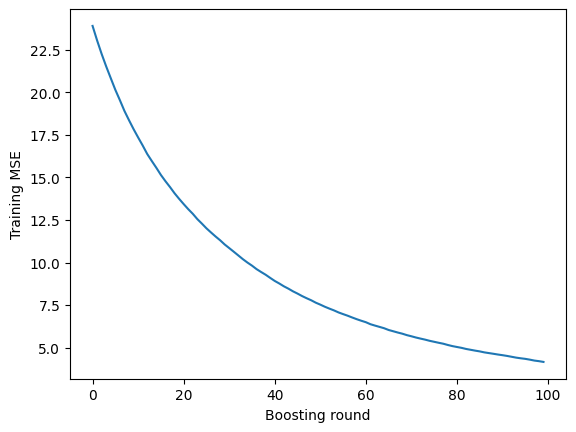

In [2]:
def fit_gradient_boosting_scratch(X, y, n_estimators=100, learning_rate=0.05, max_depth=2, min_samples_leaf=5):
    X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(X) == 0:
        raise ValueError("X must be non-empty 2D and y matching 1D")
    if n_estimators < 1 or learning_rate <= 0 or max_depth < 1 or min_samples_leaf < 1:
        raise ValueError("Invalid hyperparameters")
    init = float(np.mean(y))
    current = np.full(len(y), init)
    models = []
    train_mse = []
    for _ in range(n_estimators):
        residual = y - current
        tree = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=SEED)
        tree.fit(X, residual)
        current += learning_rate * tree.predict(X)
        models.append(tree)
        train_mse.append(mean_squared_error(y, current))
    return init, models, learning_rate, train_mse

def predict_gradient_boosting_scratch(X, init, models, learning_rate):
    prediction = np.full(len(X), init, dtype=float)
    for tree in models:
        prediction += learning_rate * tree.predict(X)
    return prediction

init, trees, lr, train_mse = fit_gradient_boosting_scratch(
    X_train, y_train, n_estimators=100, learning_rate=0.05, max_depth=2, min_samples_leaf=5
)
pred_scratch = predict_gradient_boosting_scratch(X_test, init, trees, lr)
print("Scratch test MSE:", mean_squared_error(y_test, pred_scratch))
print("Scratch test R²:", r2_score(y_test, pred_scratch))
plt.plot(train_mse)
plt.xlabel("Boosting round"); plt.ylabel("Training MSE"); plt.show()


## 5. Compare with scikit-learn

We use a similar tree depth, learning rate and number of estimators. The library may use different initialization/leaf optimization and can produce different predictions, so compare the quality and training curves rather than exact equality.

In [3]:
sk = GradientBoostingRegressor(
    loss="squared_error", n_estimators=100, learning_rate=0.05,
    max_depth=2, min_samples_leaf=5, random_state=SEED
).fit(X_train, y_train)
pred_sk = sk.predict(X_test)
print("scikit-learn test MSE:", mean_squared_error(y_test, pred_sk))
print("scikit-learn test R²:", r2_score(y_test, pred_sk))
assert np.isfinite(pred_scratch).all() and np.isfinite(pred_sk).all()


scikit-learn test MSE: 5.130261804121784
scikit-learn test R²: 0.7738392789054278


## 6. Hyperparameters and best practices

- `n_estimators`: number of additive stages.
- `learning_rate`: shrinkage; smaller values usually need more trees.
- `max_depth` / `max_leaf_nodes`: controls weak learner capacity.
- `min_samples_leaf`: smooths leaf predictions and reduces variance.
- `subsample < 1`: stochastic gradient boosting; can improve generalization and reduce work.
- Validate the number of stages and use early stopping where available.
- Tune with pipelines/CV when preprocessing is needed; tree boosters typically do not need scaling.

## 7. Complexity and scale

If a base tree costs C_tree to fit and there are T rounds, the total cost is approximately O(T·C_tree), and inference evaluates all T trees. Boosting is sequential across rounds, although work within a round may be parallelized.

For very large datasets, compare histogram-based gradient boosting and specialized libraries. Keep trees shallow, use subsampling, profile inference latency, and benchmark peak memory. Dense GPU acceleration may help in GPU-focused libraries, but classic sklearn GradientBoostingRegressor is CPU-oriented.

In [4]:
assert train_mse[-1] < train_mse[0]
assert pred_scratch.shape == y_test.shape
assert np.isfinite(train_mse).all()
try:
    fit_gradient_boosting_scratch(np.array([1,2,3]), np.array([1,2,3]))
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid X shape to raise")
print("All gradient-boosting checks passed.")


All gradient-boosting checks passed.
